# CXR 이미지 전처리 · Dataset · DataLoader

PyCharm에서 열고 **위에서부터 셀을 순서대로 실행**하세요. 별도의 `.py` 파일 없이 이 노트북만으로 실행됩니다.

- 담당 범위: 샘플 이미지 전처리, 비율을 유지한 224×224 크기 조정, 3채널 변환, ImageNet 정규화, Dataset·DataLoader 준비
- 소견 순서: **심비대(Cardiomegaly) → 폐부종(Edema) → 흉수(Pleural Effusion)**
- 클래스: 원본 `0 → 0`(음성), `1 → 1`(양성), `-1 → 2`(불확실)
- 반환 형식: 이미지 `[B, 3, 224, 224]` / 정답 `[B, 3]`

**저장된 실행 결과는 가상 이미지 4장과 임의 라벨로 실제 실행한 결과입니다. 실제 환자 영상 검증이나 모델 성능평가 결과가 아닙니다.** 가상 이미지는 도형·그라데이션으로 만들었으며 흉부 X선 영상이 아닙니다.

실제 파일로 확인하려면 2번 셀에서 `RUN_MODE = "sample"`로 바꾸고 경로를 설정하세요. 전체 다운로드가 완료되면 `"full"`을 사용할 수 있습니다.

## 1. 라이브러리 준비

설치가 필요한 경우 **현재 노트북 커널과 같은 Python 환경**의 PyCharm Terminal에서 아래를 실행하세요.

```bash
python -m pip install numpy pandas Pillow matplotlib torch ipykernel
```

PyCharm에서 이 환경을 노트북 커널로 선택하세요. 설치 후에는 커널을 재시작하고 처음부터 실행하세요. 아래 셀은 설치된 라이브러리를 불러옵니다.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader



from IPython.display import display

print("라이브러리 준비 완료")
print("PyTorch:", torch.__version__)
print("사용 가능한 장치:", "cuda" if torch.cuda.is_available() else "cpu")

라이브러리 준비 완료
PyTorch: 2.14.1+cpu
사용 가능한 장치: cpu


## 2. 실행 모드와 경로 설정

| 모드 | 필요한 파일 | 확인하는 내용 |
|---|---|---|
| `demo` (기본값) | 없음: 가상 이미지·CSV 자동 생성 | 전처리와 배치 출력 동작 |
| `sample` | 선택한 split CSV 1개 + CSV에 포함된 JPG 일부 | 실제 파일 연결과 샘플 전처리 |
| `full` | train.csv, val.csv, test.csv + 해당 JPG 전체 | split별 DataLoader 구성 |

`sample`에서 `SAMPLE_SPLIT = "train"`이면 `train.csv`만 읽습니다. 검사 단위 최종 라벨 CSV만으로는 JPG를 연결할 수 없으므로, **이미지와 라벨을 연결한 팀원의 CSV**를 사용하세요.

CSV 필수 컬럼: `subject_id`, `study_id`, `dicom_id`, `ViewPosition`, `split`, `Cardiomegaly`, `Edema`, `Pleural Effusion`.
`ViewPosition`은 AP/PA, `split`은 train/validate/test입니다. 파일 이름은 **val.csv**, 그 안의 split 값은 **validate**입니다. 라벨은 원본 값 0/1/-1을 사용합니다.

- `IMAGE_LAYOUT = "flat"`: `IMAGE_ROOT/dicom_id.jpg`
- `IMAGE_LAYOUT = "mimic"`: `IMAGE_ROOT/files/pXX/p환자번호/s검사번호/dicom_id.jpg` (`IMAGE_ROOT`는 files 바로 위 폴더)

노트북에는 `__file__`이 없으므로 현재 작업 폴더를 기준으로 합니다. 아래 출력에서 기준 경로를 확인하세요. 실제 경로는 `Path(r"D:\cxr_samples")`처럼 직접 지정해도 됩니다.

In [2]:
# demo: 가상 데이터 / sample: 실제 샘플 / full: 전체 split
RUN_MODE = "demo"
PROJECT_DIR = Path.cwd()
CSV_DIR = PROJECT_DIR / "data" / "processed"
IMAGE_ROOT = PROJECT_DIR / "data" / "images"
IMAGE_LAYOUT = "mimic"  # 한 폴더에 JPG를 모았다면 "flat"
SAMPLE_SPLIT = "train"
SAMPLE_SIZE = 4
IMAGE_SIZE = 224
BATCH_SIZE = 4
NUM_WORKERS = 0  # Windows·노트북에서는 0으로 시작
SHOW_PREVIEW = True
SEED = 42

TARGET_LABELS = ["Cardiomegaly", "Edema", "Pleural Effusion"]
CLASS_MAP = {0: 0, 1: 1, -1: 2}
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)
CSV_NAMES = {"train": "train.csv", "validate": "val.csv", "test": "test.csv"}

print("실행 모드:", RUN_MODE)
print("기준 폴더:", PROJECT_DIR)
print("실제 CSV 경로:", CSV_DIR)
print("실제 이미지 경로:", IMAGE_ROOT)
display(pd.DataFrame({"원본 라벨": [0, 1, -1], "클래스 번호": [0, 1, 2],
                      "의미": ["음성", "양성", "불확실"]}))

실행 모드: demo
기준 폴더: /workspace/scratch/d1861070926a
실제 CSV 경로: /workspace/scratch/d1861070926a/data/processed
실제 이미지 경로: /workspace/scratch/d1861070926a/data/images


,원본 라벨,클래스 번호,의미
0,0,0,음성
1,1,1,양성
2,-1,2,불확실


## 3. CSV 검사와 이미지 경로 연결

기존 Python 코드의 연결 규칙을 유지합니다. 빈 라벨·잘못된 클래스·중복 이미지·잘못된 split은 오류로 알려줍니다. 결측 라벨을 임의로 음성으로 채우지 않습니다.

In [3]:
def validate_labels(df):
    """최종 CSV에서 NaN을 다시 0으로 바꾸지 않고 잘못된 값을 알립니다."""
    missing = set(TARGET_LABELS) - set(df.columns)
    if missing:
        raise ValueError(f"라벨 컬럼이 없습니다: {sorted(missing)}")
    labels = df[TARGET_LABELS].apply(pd.to_numeric, errors="raise")
    if labels.isna().any().any():
        raise ValueError("최종 CSV에 NaN 라벨이 있습니다. 팀원 최종 라벨표를 확인하세요.")
    if not labels.isin(list(CLASS_MAP)).all().all():
        raise ValueError("원본 라벨은 0, 1, -1만 가능합니다. 이미 2로 변환된 CSV도 확인하세요.")
    return labels.astype("int64")


def read_split_csv(csv_dir, image_root, split, image_layout="mimic"):
    """이미 라벨이 연결된 최종 선정 CSV를 읽어 image_path를 추가합니다."""
    if split not in CSV_NAMES:
        raise ValueError(f"split은 {list(CSV_NAMES)} 중 하나여야 합니다.")
    if image_layout not in {"mimic", "flat"}:
        raise ValueError("IMAGE_LAYOUT은 'mimic' 또는 'flat'이어야 합니다.")
    csv_path = Path(csv_dir) / CSV_NAMES[split]
    if not csv_path.is_file():
        raise FileNotFoundError(f"최종 선정 CSV가 없습니다: {csv_path}")

    # 식별자를 문자열로 읽어 환자/검사 번호에 .0이 붙는 일을 방지합니다.
    df = pd.read_csv(csv_path, dtype={
        "subject_id": "string", "study_id": "string", "dicom_id": "string"
    })
    required = {"subject_id", "study_id", "dicom_id", "ViewPosition", "split"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{csv_path.name}의 필수 컬럼이 없습니다: {sorted(missing)}")
    if df.empty:
        raise ValueError(f"{csv_path.name}에 이미지 목록이 없습니다.")

    for column in ["subject_id", "study_id", "dicom_id"]:
        df[column] = df[column].str.strip()
        if df[column].isna().any() or df[column].eq("").any():
            raise ValueError(f"{csv_path.name}: {column}에 빈 식별자가 있습니다.")
    for column in ["subject_id", "study_id"]:
        if not df[column].str.fullmatch(r"[0-9]+").all():
            raise ValueError(f"{column}는 정수 번호여야 합니다. CSV에 .0 등이 있는지 확인하세요.")
    if not df["dicom_id"].str.fullmatch(r"[A-Za-z0-9-]+").all():
        raise ValueError("dicom_id에는 확장자나 경로 대신 원본 이미지 식별자를 넣으세요.")
    if df["dicom_id"].duplicated().any():
        raise ValueError(f"{csv_path.name}: dicom_id가 중복되어 있습니다.")
    if not df["ViewPosition"].isin(["AP", "PA"]).all():
        raise ValueError(f"{csv_path.name}: AP/PA 이외의 영상이 있습니다. 선정 CSV를 확인하세요.")
    if not df["split"].eq(split).all():
        raise ValueError(f"{csv_path.name}: split 값이 '{split}'과 일치하지 않습니다.")
    df[TARGET_LABELS] = validate_labels(df)

    image_root = Path(image_root).expanduser().resolve()
    paths = []
    for row in df.itertuples(index=False):
        if image_layout == "flat":
            path = image_root / f"{row.dicom_id}.jpg"
        else:
            path = (image_root / "files" / f"p{row.subject_id[:2]}"
                    / f"p{row.subject_id}" / f"s{row.study_id}" / f"{row.dicom_id}.jpg")
        paths.append(str(path))
    # CSV의 기존 경로 대신 이 컴퓨터의 IMAGE_ROOT를 기준으로 생성합니다.
    df["image_path"] = paths
    return df.reset_index(drop=True)

## 4. 크기 조정 · 3채널 변환 · 정규화

흑백 → 검은 정사각형 패딩 → 224×224 → 255로 나누기 → 동일한 흑백값을 3채널로 복제 → 채널별 `(값 − 평균) / 표준편차` 순서입니다.

ImageNet 정규화 이후에는 값이 0~1을 벗어나도 정상입니다. 채널별 평균·표준편차가 다르기 때문에 **최종 정규화 텐서의 세 채널은 서로 달라집니다.** 화면 표시에는 역정규화를 사용합니다. 학습 코드에서 같은 정규화를 다시 적용하지 마세요.

In [4]:
def resize_with_padding(image, image_size=224):
    """긴 변 기준 정사각형에 가운데 배치한 뒤 축소해 비율을 유지합니다."""
    if image_size <= 0:
        raise ValueError("image_size는 양수여야 합니다.")
    gray = image.convert("L")
    width, height = gray.size
    side = max(width, height)
    canvas = Image.new("L", (side, side), color=0)
    canvas.paste(gray, ((side - width) // 2, (side - height) // 2))
    return canvas.resize((image_size, image_size), Image.Resampling.BILINEAR)


def preprocess_image(image, image_size=224):
    resized = resize_with_padding(image, image_size)
    pixels = np.array(resized, dtype=np.float32) / 255.0
    # [H, W] → [1, H, W] → [3, H, W]; 색을 추가하는 것이 아닌 동일 흑백값 복제.
    tensor = torch.from_numpy(pixels).unsqueeze(0).repeat(3, 1, 1)
    mean = tensor.new_tensor(MEAN).view(3, 1, 1)
    std = tensor.new_tensor(STD).view(3, 1, 1)
    return (tensor - mean) / std


def denormalize_image(tensor):
    """화면 표시용: ImageNet 정규화를 되돌려 0~1 영상으로 만듭니다."""
    mean = tensor.new_tensor(MEAN).view(3, 1, 1)
    std = tensor.new_tensor(STD).view(3, 1, 1)
    return (tensor * std + mean).clamp(0, 1)

## 5. Dataset과 DataLoader 함수

Dataset은 이미지 한 장 `[3, 224, 224]`와 소견별 정답 `[3]`을 반환합니다. 세 소견 각각 3개 클래스를 예측하는 기존 U-multiclass 설정입니다.

`sample`은 실제 존재하는 JPG만 골라 확인합니다. `full`은 누락 이미지가 있으면 중단하고 split 간 환자·검사·이미지 중복도 검사합니다. 새 split을 만들지 않습니다.

In [5]:
class CXRDataset(Dataset):
    def __init__(self, dataframe, image_size=224):
        if dataframe.empty:
            raise ValueError("Dataset에 넣을 이미지가 없습니다.")
        if "image_path" not in dataframe.columns:
            raise ValueError("image_path가 없습니다. read_split_csv()를 먼저 실행하세요.")
        self.df = dataframe.reset_index(drop=True).copy()
        self.image_size = image_size
        raw = validate_labels(self.df)
        mapped = raw.replace(CLASS_MAP).to_numpy(dtype=np.int64)
        self.labels = torch.from_numpy(mapped)  # [N, 3], torch.long

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        image_path = Path(self.df.iloc[index]["image_path"])
        if not image_path.is_file():
            raise FileNotFoundError(f"이미지 파일이 없습니다: {image_path}")
        try:
            with Image.open(image_path) as image:
                image_tensor = preprocess_image(image, self.image_size)
        except (OSError, ValueError) as exc:
            raise RuntimeError(f"이미지 읽기/전처리에 실패했습니다: {image_path}") from exc
        return image_tensor, self.labels[index]


# 5. 전체 split별 DataLoader (전체 다운로드 완료 후 사용) -----------------------
def build_dataloaders(csv_dir, image_root, image_layout="mimic", image_size=224,
                      batch_size=4, num_workers=0, seed=42):
    frames = {
        split: read_split_csv(csv_dir, image_root, split, image_layout)
        for split in CSV_NAMES
    }
    # 공식 split을 다시 나누지 않습니다. 환자/검사/이미지 중복이 있으면 중단합니다.
    pairs = [("train", "validate"), ("train", "test"), ("validate", "test")]
    for first, second in pairs:
        for column in ["subject_id", "study_id", "dicom_id"]:
            overlap = set(frames[first][column]) & set(frames[second][column])
            if overlap:
                raise ValueError(f"{first}–{second}: {column} 중복 {len(overlap)}개")

    loaders = {}
    for split, df in frames.items():
        exists = df["image_path"].map(lambda p: Path(p).is_file())
        if not exists.all():
            example = df.loc[~exists, "image_path"].iloc[0]
            raise FileNotFoundError(
                f"{split}: 미다운로드 이미지 {(~exists).sum()}장. 예: {example}\n"
                "전체 연결은 다운로드 완료 후 실행하세요. 샘플 확인은 RUN_MODE='sample'로 하세요."
            )
        dataset = CXRDataset(df, image_size=image_size)
        loaders[split] = DataLoader(
            dataset, batch_size=batch_size, shuffle=(split == "train"),
            num_workers=num_workers, pin_memory=torch.cuda.is_available(),
            drop_last=False, generator=torch.Generator().manual_seed(seed)
        )
    return loaders


# 6. 샘플 확인: 최종 CSV에 있고 실제로 내려받은 이미지 중 일부만 사용 -----------
def build_sample_dataset(csv_dir, image_root, split="train", image_layout="mimic",
                         sample_size=4, image_size=224):
    if sample_size < 1:
        raise ValueError("SAMPLE_SIZE는 1 이상이어야 합니다.")
    df = read_split_csv(csv_dir, image_root, split, image_layout)
    exists = df["image_path"].map(lambda p: Path(p).is_file())
    available = df.loc[exists].copy()
    print(f"{split} 선정 {len(df):,}장 / 로컬에 존재 {len(available):,}장")
    if available.empty:
        raise FileNotFoundError(
            "최종 CSV와 연결되는 로컬 JPG가 없습니다. IMAGE_ROOT / IMAGE_LAYOUT을 확인하세요.\n"
            f"첫 예상 경로: {df['image_path'].iloc[0]}"
        )

    # 가능한 경우 실제 -1 라벨 샘플을 앞에 넣어 클래스 2 변환도 확인합니다.
    uncertain = available[TARGET_LABELS].eq(-1).any(axis=1)
    ordered = pd.concat([available.loc[uncertain], available.loc[~uncertain]])
    sample = ordered.head(sample_size).reset_index(drop=True)
    if not uncertain.any():
        print("현재 로컬 이미지에는 원본 -1 라벨이 없습니다. 실제 불확실 샘플 검증은 추후 필요합니다.")
    print("주의: 이 샘플 Dataset은 동작 확인용이며 전체 학습/성능 평가용이 아닙니다.")
    return CXRDataset(sample, image_size=image_size)


def inspect_batch(dataset, batch_size=4, show_preview=True):
    # 그림과 CSV 행 순서를 일치시키기 위해 확인용 loader는 항상 shuffle=False.
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    images, labels = next(iter(loader))
    print("이미지 배치 크기:", images.shape)
    print("이미지 자료형:", images.dtype)
    print("정규화 후 이미지 범위:", float(images.min()), "~", float(images.max()))
    print("라벨 배치 크기:", labels.shape)
    print("라벨 자료형:", labels.dtype)
    print("변환된 정답:\n", labels)
    # 정상값/양성/불확실의 순서가 아닌 음성/양성/불확실의 순서입니다.
    raw = dataset.df[TARGET_LABELS]
    print("세 소견 모두 불확실한 이미지 수:", int(raw.eq(-1).all(axis=1).sum()))
    for i in range(len(images)):
        row = dataset.df.iloc[i]
        original = row[TARGET_LABELS].astype(int).tolist()
        print(f"{row['dicom_id']} | 원본 {original} → 클래스 {labels[i].tolist()}")

    if show_preview:
        figure, axes = plt.subplots(len(images), 2, figsize=(9, 4 * len(images)), squeeze=False)
        for i in range(len(images)):
            row = dataset.df.iloc[i]
            with Image.open(row["image_path"]) as image:
                axes[i, 0].imshow(image.convert("L"), cmap="gray", vmin=0, vmax=255)
            # 정규화된 값을 직접 그리지 않고 먼저 정규화를 되돌립니다.
            gray = denormalize_image(images[i]).mean(dim=0).numpy()
            axes[i, 1].imshow(gray, cmap="gray", vmin=0, vmax=1)
            axes[i, 0].set_title(f"Original | {row['ViewPosition']}")
            axes[i, 1].set_title(f"Processed | classes={labels[i].tolist()}")
            for axis in axes[i]:
                axis.axis("off")
        figure.suptitle("Label order: Cardiomegaly / Edema / Pleural Effusion")
        figure.tight_layout()
        plt.show()
        plt.close(figure)

## 6. 실행 데이터 준비

`demo`에서는 시스템 임시 폴더에 가상 이미지와 train.csv를 만듭니다. 실제 프로젝트의 CSV나 JPG는 변경하지 않습니다. 가상 라벨은 영상 내용과 관계없이 변환 규칙을 검증하기 위한 값입니다.

`sample`·`full`에서는 위에서 지정한 실제 경로를 사용합니다. 실제 파일 경로가 틀렸다면 이 셀 또는 다음 셀에서 오류가 표시됩니다.

In [6]:
def create_demo_data():
    import tempfile
    demo_root = Path(tempfile.mkdtemp(prefix="cxr_preprocessing_demo_"))
    csv_dir = demo_root / "processed"
    image_root = demo_root / "images"
    csv_dir.mkdir()
    image_root.mkdir()
    sizes = [(320, 480), (520, 300), (400, 400), (280, 420)]
    raw_labels = [[1, -1, 0], [0, 1, -1], [-1, 0, 1], [0, 0, 0]]
    rows = []
    for i, ((width, height), labels) in enumerate(zip(sizes, raw_labels)):
        yy, xx = np.mgrid[0:height, 0:width]
        # 실제 CXR가 아닌 도형·그라데이션 동작 확인용 이미지
        pattern = 25 + 160 * xx / max(width - 1, 1)
        circle = ((xx - width / 2) / (width / 3))**2 + ((yy - height / 2) / (height / 3))**2 < 1
        pattern = np.where(circle, 225 - 100 * yy / height, pattern)
        pattern[height//4:height//4 + 12, :] = 255
        dicom_id = f"demo-{i+1:02d}"
        Image.fromarray(np.clip(pattern, 0, 255).astype(np.uint8)).save(image_root / f"{dicom_id}.jpg")
        rows.append({"subject_id": str(90000001 + i), "study_id": str(99000001 + i),
                     "dicom_id": dicom_id, "ViewPosition": "AP" if i % 2 == 0 else "PA",
                     "split": "train", **dict(zip(TARGET_LABELS, labels))})
    pd.DataFrame(rows).to_csv(csv_dir / "train.csv", index=False)
    return csv_dir, image_root

if RUN_MODE == "demo":
    active_csv_dir, active_image_root = create_demo_data()
    active_layout, active_split = "flat", "train"
    print("주의: 가상 이미지 4장·임의 라벨을 사용합니다. 실제 환자 영상이 아닙니다.")
elif RUN_MODE in {"sample", "full"}:
    active_csv_dir, active_image_root = CSV_DIR, IMAGE_ROOT
    active_layout, active_split = IMAGE_LAYOUT, SAMPLE_SPLIT
    print("사용자 지정 실제 파일을 사용합니다.")
else:
    raise ValueError("RUN_MODE는 demo, sample, full 중 하나여야 합니다.")

frame = read_split_csv(active_csv_dir, active_image_root, active_split, active_layout)
print("선택한 CSV 행 수:", len(frame))
display(frame[["dicom_id", "ViewPosition", "split"] + TARGET_LABELS].head())

주의: 가상 이미지 4장·임의 라벨을 사용합니다. 실제 환자 영상이 아닙니다.
선택한 CSV 행 수: 4


,dicom_id,ViewPosition,split,Cardiomegaly,Edema,Pleural Effusion
0,demo-01,AP,train,1,-1,0
1,demo-02,PA,train,0,1,-1
2,demo-03,AP,train,-1,0,1
3,demo-04,PA,train,0,0,0


## 7. Dataset 연결과 라벨 변환 결과

아래 표에서 `*_raw`는 원본 CSV 값, `*_class`는 Dataset이 반환하는 클래스 번호입니다. `-1 → 2`가 적용되는지 확인하세요. 샘플은 불확실 라벨이 있는 이미지를 우선 보여줍니다.

In [7]:
dataset = build_sample_dataset(
    active_csv_dir, active_image_root, active_split, active_layout,
    sample_size=SAMPLE_SIZE, image_size=IMAGE_SIZE
)
raw = dataset.df[TARGET_LABELS].astype(int).add_suffix("_raw")
mapped = pd.DataFrame(dataset.labels.numpy(), columns=[f"{name}_class" for name in TARGET_LABELS])
comparison = pd.concat([dataset.df[["dicom_id"]], raw, mapped], axis=1)
display(comparison)
print("Dataset 이미지 수:", len(dataset))
one_image, one_label = dataset[0]
print("이미지 한 장:", one_image.shape, one_image.dtype)
print("정답 한 장:", one_label.shape, one_label.dtype, one_label.tolist())

train 선정 4장 / 로컬에 존재 4장
주의: 이 샘플 Dataset은 동작 확인용이며 전체 학습/성능 평가용이 아닙니다.
Dataset 이미지 수: 4
이미지 한 장: torch.Size([3, 224, 224]) torch.float32
정답 한 장: torch.Size([3]) torch.int64 [1, 2, 0]


,dicom_id,Cardiomegaly_raw,Edema_raw,Pleural Effusion_raw,Cardiomegaly_class,Edema_class,Pleural Effusion_class
0,demo-01,1,-1,0,1,2,0
1,demo-02,0,1,-1,0,1,2
2,demo-03,-1,0,1,2,0,1
3,demo-04,0,0,0,0,0,0


## 8. DataLoader 배치 결과와 이미지 비교

왼쪽은 원본, 오른쪽은 패딩·크기 조정 이후 이미지입니다. 오른쪽은 시각화를 위해 역정규화한 모습이며, 모델에 전달할 때는 정규화된 텐서를 그대로 사용합니다.

이미지 배치 크기: torch.Size([4, 3, 224, 224])
이미지 자료형: torch.float32
정규화 후 이미지 범위: -2.1179039478302 ~ 2.640000104904175
라벨 배치 크기: torch.Size([4, 3])
라벨 자료형: torch.int64
변환된 정답:
 tensor([[1, 2, 0],
        [0, 1, 2],
        [2, 0, 1],
        [0, 0, 0]])
세 소견 모두 불확실한 이미지 수: 0
demo-01 | 원본 [1, -1, 0] → 클래스 [1, 2, 0]
demo-02 | 원본 [0, 1, -1] → 클래스 [0, 1, 2]
demo-03 | 원본 [-1, 0, 1] → 클래스 [2, 0, 1]
demo-04 | 원본 [0, 0, 0] → 클래스 [0, 0, 0]


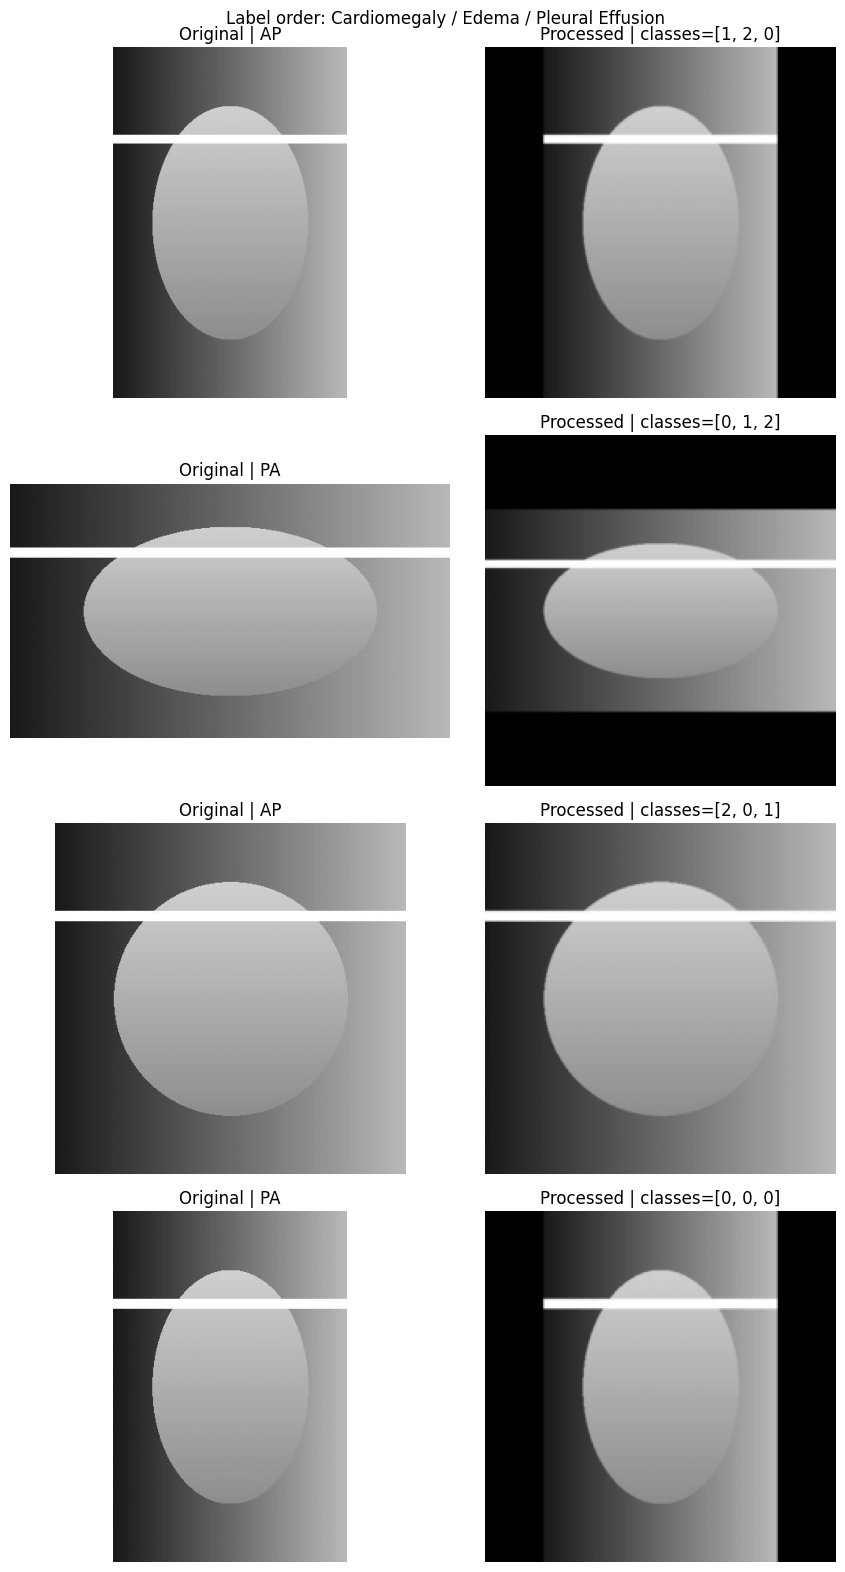

In [8]:
# 이 loader를 이후 학습 코드에 전달할 수 있습니다.
# 현재는 동작 확인용으로 shuffle=False를 사용합니다.
loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
images, labels = next(iter(loader))
inspect_batch(dataset, batch_size=BATCH_SIZE, show_preview=SHOW_PREVIEW)

## 9. 전처리 결과 자동 확인

실제 배치의 채널 수·크기·자료형·유한값과 CSV 원본 라벨 대비 변환 결과를 확인합니다. 역정규화 후 세 채널이 같은 흑백 영상으로 돌아오는지도 확인합니다. 이 검사는 전처리 동작 검사이며 모델 성능 검사에 해당하지 않습니다.

In [9]:
assert images.shape == (len(labels), 3, IMAGE_SIZE, IMAGE_SIZE)
assert images.dtype == torch.float32
assert labels.shape == (len(images), len(TARGET_LABELS))
assert labels.dtype == torch.long
assert torch.isfinite(images).all()
assert set(labels.flatten().tolist()).issubset({0, 1, 2})
expected = torch.tensor(dataset.df[TARGET_LABELS].replace(CLASS_MAP).to_numpy(dtype=np.int64))
assert torch.equal(labels, expected[:len(labels)])
restored = denormalize_image(images[0])
assert torch.allclose(restored[0], restored[1], atol=1e-6)
assert torch.allclose(restored[1], restored[2], atol=1e-6)
print("검증 통과: 이미지 크기·3채널·자료형·유한값·라벨 변환·역정규화")
print("주의: 실제 파일 연결 검증은 RUN_MODE='sample'로 실행해야 합니다." if RUN_MODE == "demo"
      else "실제 샘플 연결과 전처리 동작 확인 완료. 전체 데이터 검증과는 구분하세요.")

검증 통과: 이미지 크기·3채널·자료형·유한값·라벨 변환·역정규화
주의: 실제 파일 연결 검증은 RUN_MODE='sample'로 실행해야 합니다.


## 10. 전체 다운로드 완료 후: split별 DataLoader

전체 파일을 받은 다음 **2번 셀에서 `RUN_MODE = "full"`로 변경하고 처음부터 실행**하세요. 이 셀은 train·validate·test DataLoader를 구성합니다. `demo`·`sample`에서는 안내만 출력합니다.

학습 담당자에게 전달할 값은 `loaders["train"]`, `loaders["validate"]`, `loaders["test"]`입니다. 노트북의 Dataset은 정규화를 이미 적용합니다.

In [10]:
if RUN_MODE == "full":
    loaders = build_dataloaders(
        CSV_DIR, IMAGE_ROOT, IMAGE_LAYOUT, IMAGE_SIZE, BATCH_SIZE, NUM_WORKERS, SEED
    )
    for split, split_loader in loaders.items():
        x, y = next(iter(split_loader))
        print(f"{split}: {len(split_loader.dataset):,}장 | 이미지 {tuple(x.shape)} | 정답 {tuple(y.shape)}")
    print("전체 split별 DataLoader 준비 완료")
else:
    print("전체 연결은 생략했습니다. 다운로드 완료 후 RUN_MODE='full'로 실행하세요.")

전체 연결은 생략했습니다. 다운로드 완료 후 RUN_MODE='full'로 실행하세요.


## 팀원에게 전달할 기준

- 이미지: `[B, 3, 224, 224]`, `torch.float32`
- 정답: `[B, 3]`, `torch.long`
- 라벨 순서: Cardiomegaly → Edema → Pleural Effusion
- 클래스: 음성 0 / 양성 1 / 불확실 2 (CSV의 -1을 Dataset에서 변환)
- 비율 유지 패딩·크기 조정·3채널 복제·ImageNet 정규화 적용 완료
- 모델 학습 시 같은 전처리를 중복 적용하지 않기

**저장된 출력은 demo 실행 결과입니다. 실제 연결 결과를 제출하려면 sample 또는 full로 실제 파일을 실행한 뒤 노트북을 저장하세요.**